# 01 - Extracting Data from ArXiv into a Pandas DataFrame and Saving it as JSON

In [1]:
pip install --upgrade pip -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [3]:
import requests
import pandas as pd
import json
import xml.etree.ElementTree as ET

# Namespace for ArXiv's Atom-based XML format.
ARXIV_NAMESPACE = '{http://www.w3.org/2005/Atom}'

def extract_from_arxiv(search_query='cat:cs.AI', max_results=100, json_file_path='files/arxiv_dataset.json'):
    """
    Fetches papers from the ArXiv API based on a search query, saves them as JSON,
    and returns a pandas DataFrame.

    Args:
        search_query (str): The search query for ArXiv (default is 'cat:cs.AI').
        max_results (int): The maximum number of results to retrieve (default is 100).
        json_file_path (str): File path where JSON data will be saved.

    Returns:
        pd.DataFrame: DataFrame containing the extracted apper information.
    """

    # Construct the URL for the API request.
    url = f'http://export.arxiv.org/api/query?search_query={search_query}&max_results={max_results}'

    # Send a GET request to the ArXiv API.
    response = requests.get(url)

    # Parse the XML response.
    root = ET.fromstring(response.content)

    papers = []

    # Loop through each "entry" in the XML, representing a single paper.
    for entry in root.findall(f'{ARXIV_NAMESPACE}entry'):
        title = entry.find(f'{ARXIV_NAMESPACE}title').text.strip()
        summary = entry.find(f'{ARXIV_NAMESPACE}summary').text.strip()

        # Get the authors of the paper
        author_elements = entry.findall(f'{ARXIV_NAMESPACE}author')
        authors = [author.find(f'{ARXIV_NAMESPACE}name').text for author in author_elements]

        # Get the paper URL
        paper_url = entry.find(f'{ARXIV_NAMESPACE}id').text
        arxiv_id = paper_url.split('/')[-1]

        # Check for the PDF link.
        pdf_link = next((link.attrib['href'] for link in entry.findall(f'{ARXIV_NAMESPACE}link')
                         if link.attrib.get('title') == 'pdf'), None)

        papers.append({
            'title': title,
            'summary': summary,
            'authors': authors,
            'arxiv_id': arxiv_id,
            'url': paper_url,
            'pdf_link': pdf_link
        })

    # Convert list into a pandas DataFrame.
    df = pd.DataFrame(papers)

    # Save the DataFrame to a JSON file.
    with open(json_file_path, 'w', encoding='utf-8') as f:
        json.dump(papers, f, ensure_ascii=False, indent=4)
        print(f'Data saved to {json_file_path} ...')

    return df

In [4]:
df = extract_from_arxiv(max_results=20)

Data saved to files/arxiv_dataset.json ...


In [5]:
import json
file_name = 'files/arxiv_dataset.json'
with open(file_name, 'r') as file:
    data = json.load(file)

print(data)

[{'title': 'A Deep Reinforcement Learning Approach for Ramp Metering Based on Traffic Video Data', 'summary': 'Ramp metering that uses traffic signals to regulate vehicle flows from the on-ramps has been widely implemented to improve vehicle mobility of the freeway. Previous studies generally update signal timings in real-time based on predefined traffic measures collected by point detectors, such as traffic volumes and occupancies. Comparing with point detectors, traffic cameras-which have been increasingly deployed on road networks-could cover larger areas and provide more detailed traffic information. In this work, we propose a deep reinforcement learning (DRL) method to explore the potential of traffic video data in improving the efficiency of ramp metering. The proposed method uses traffic video frames as inputs and learns the optimal control strategies directly from the high-dimensional visual inputs. A real-world case study demonstrates that, in comparison with a state-of-the-pr

In [6]:
import pandas as pd
df = pd.DataFrame(data)
df.sample(n=5)

,title,summary,authors,arxiv_id,url,pdf_link
5,Skeleton-based Approaches based on Machine Vis...,"Recently, skeleton-based approaches have achie...","[Jie Li, Binglin Li, Min Gao]",2012.12447v1,http://arxiv.org/abs/2012.12447v1,https://arxiv.org/pdf/2012.12447v1
9,Compliance Generation for Privacy Documents un...,Most prominent research today addresses compli...,"[David Restrepo Amariles, Aurore ClÃ©ment Trou...",2012.12718v1,http://arxiv.org/abs/2012.12718v1,https://arxiv.org/pdf/2012.12718v1
15,How to define co-occurrence in different domai...,This position paper presents a comparative stu...,[Mathieu Roche],1904.08010v1,http://arxiv.org/abs/1904.08010v1,https://arxiv.org/pdf/1904.08010v1
0,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,https://arxiv.org/pdf/2012.12104v1
8,Dynamic-K Recommendation with Personalized Dec...,"In this paper, we investigate the recommendati...","[Yan Gao, Jiafeng Guo, Yanyan Lan, Huaming Liao]",2012.13569v1,http://arxiv.org/abs/2012.13569v1,https://arxiv.org/pdf/2012.13569v1


# 02 - Downloading the Research Papers (PDFs)

In [7]:
import pandas as pd
import requests
import os

def download_pdfs(df, download_folder='files'):
    """
    Downloads PDFs from URLs listed in the DataFrame and saves them to a specified folder.
    The file names are stored in a new column 'pdf_file_name' in the DataFrame.

    Args:
        df (pd.DataFrame): DataFrame containing a 'pdf_link' column with URLs to download.
        download_folder (str): Path to the folder where PDFs will be saved (default is 'files').

    Returns:
        pd.DataFrame: The original DataFrame with an additional 'pdf_file_name' column containing
                        the paths of the downloaded PDF files or None if the download failed.
    """

    if not os.path.exists(download_folder):
        os.makedirs(download_folder)

    pdf_file_names = []

    # Loop through each row to download PDFs
    for index, row in df.iterrows():
        pdf_link = row['pdf_link']

        try:
            response = requests.get(pdf_link)
            response.raise_for_status()

            file_name = os.path.join(download_folder, pdf_link.split('/')[-1]) + '.pdf'
            pdf_file_names.append(file_name)

            # Save the downloaded PDF
            with open(file_name, 'wb') as f:
                f.write(response.content)

            print(f'PDF downloaded successfully and saved as {file_name}')

        except requests.exceptions.RequestException as e:
            print(f'Failed to download the PDF: {e}')
            pdf_file_names.append(None)

    df['pdf_file_name'] = pdf_file_names

    return df

In [8]:
df = download_pdfs(df)

PDF downloaded successfully and saved as files\2012.12104v1.pdf
PDF downloaded successfully and saved as files\2012.13026v1.pdf
PDF downloaded successfully and saved as files\2012.13293v1.pdf
PDF downloaded successfully and saved as files\2012.13315v1.pdf
PDF downloaded successfully and saved as files\2012.13391v2.pdf
PDF downloaded successfully and saved as files\2012.12447v1.pdf
PDF downloaded successfully and saved as files\2012.12634v1.pdf
PDF downloaded successfully and saved as files\2012.11903v1.pdf
PDF downloaded successfully and saved as files\2012.13569v1.pdf
PDF downloaded successfully and saved as files\2012.12718v1.pdf
PDF downloaded successfully and saved as files\2012.13666v1.pdf
PDF downloaded successfully and saved as files\2012.13677v1.pdf
PDF downloaded successfully and saved as files\2012.13779v1.pdf
PDF downloaded successfully and saved as files\2012.14005v1.pdf
PDF downloaded successfully and saved as files\1904.07934v2.pdf
PDF downloaded successfully and saved as

In [9]:
df

,title,summary,authors,arxiv_id,url,pdf_link,pdf_file_name
0,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,https://arxiv.org/pdf/2012.12104v1,files\2012.12104v1.pdf
1,Rethink AI-based Power Grid Control: Diving In...,"Recently, deep reinforcement learning (DRL)-ba...","[Xiren Zhou, Siqi Wang, Ruisheng Diao, Desong ...",2012.13026v1,http://arxiv.org/abs/2012.13026v1,https://arxiv.org/pdf/2012.13026v1,files\2012.13026v1.pdf
2,Fuzzy Commitments Offer Insufficient Protectio...,"In this work, we study the protection that fuz...","[Danny Keller, Margarita Osadchy, Orr Dunkelman]",2012.13293v1,http://arxiv.org/abs/2012.13293v1,https://arxiv.org/pdf/2012.13293v1,files\2012.13293v1.pdf
3,Generalization in portfolio-based algorithm se...,Portfolio-based algorithm selection has seen t...,"[Maria-Florina Balcan, Tuomas Sandholm, Ellen ...",2012.13315v1,http://arxiv.org/abs/2012.13315v1,https://arxiv.org/pdf/2012.13315v1,files\2012.13315v1.pdf
4,"I like fish, especially dolphins: Addressing C...",To quantify how well natural language understa...,"[Yixin Nie, Mary Williamson, Mohit Bansal, Dou...",2012.13391v2,http://arxiv.org/abs/2012.13391v2,https://arxiv.org/pdf/2012.13391v2,files\2012.13391v2.pdf
5,Skeleton-based Approaches based on Machine Vis...,"Recently, skeleton-based approaches have achie...","[Jie Li, Binglin Li, Min Gao]",2012.12447v1,http://arxiv.org/abs/2012.12447v1,https://arxiv.org/pdf/2012.12447v1,files\2012.12447v1.pdf
6,Overview of FPGA deep learning acceleration ba...,"In recent years, deep learning has become more...",[Simin Liu],2012.12634v1,http://arxiv.org/abs/2012.12634v1,https://arxiv.org/pdf/2012.12634v1,files\2012.12634v1.pdf
7,Modelling Human Routines: Conceptualising Soci...,Our routines play an important role in a wide ...,"[Rijk Mercuur, Virginia Dignum, Catholijn M. J...",2012.11903v1,http://arxiv.org/abs/2012.11903v1,https://arxiv.org/pdf/2012.11903v1,files\2012.11903v1.pdf
8,Dynamic-K Recommendation with Personalized Dec...,"In this paper, we investigate the recommendati...","[Yan Gao, Jiafeng Guo, Yanyan Lan, Huaming Liao]",2012.13569v1,http://arxiv.org/abs/2012.13569v1,https://arxiv.org/pdf/2012.13569v1,files\2012.13569v1.pdf
9,Compliance Generation for Privacy Documents un...,Most prominent research today addresses compli...,"[David Restrepo Amariles, Aurore ClÃ©ment Trou...",2012.12718v1,http://arxiv.org/abs/2012.12718v1,https://arxiv.org/pdf/2012.12718v1,files\2012.12718v1.pdf


# 03 Loading and Splitting PDF Files into Chunks, Expanding the DataFrame

In [10]:
# load and split
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

def load_and_chunk_pdf(pdf_file_name, chunk_size=512):
    """
    Loads a PDF file and splits its content into chunks of a specified size.

    Args:
        file (str): Path to the PDF file to be loaded.
        chunk_size (int): The maximum size of each chunk in characters (default is 512).

    Returns:
        List[Document]: A list of document chunks.
    """

    print(f'Loading and splitting into chunks: {pdf_file_name}')

    # Load the content of the PDF
    loader = PyPDFLoader(pdf_file_name)
    data = loader.load()

    # Split the content into chunks with slight overlap to preserve context
    text_splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=64)
    chunks = text_splitter.split_documents(data)

    return chunks

In [11]:
def expand_df(df):
    """
    Expands each row in the DataFrame by splitting PDF documents into chunks.

    Args:
        df (pd.DataFrame): DataFrame containing 'pdf_file_name', 'arxiv_id', 'title', 'summary', 
                           'authors', and 'url' columns.

    Returns:
        pd.DataFrame: A new DataFrame where each row represents a chunk of the original document, 
                      with additional metadata such as chunk identifiers and relationships to 
                      adjacent chunks.
    """

    expanded_rows = [] # List to store expanded rows with chunk information

    # Loop through each row in the DataFrame
    for idx, row in df.iterrows():
        try:
            chunks = load_and_chunk_pdf(row['pdf_file_name'])
        except Exception as e:
            print(f"Error processing file {row['pdf_file_name']}: {e}")
            continue

        # Loop over the chunks and construct a new DataFrame row for each
        for i, chunk in enumerate(chunks):
            prechunk_id = i-1 if i > 0 else '' # Preceding chunk ID
            postchunk_id = i+1 if i < len(chunks) -1 else '' # Following chunk ID

            expanded_rows.append({
                'id': f"{row['arxiv_id']}#{i}",  # Unique chunk identifier
                'title': row['title'],
                'summary': row['summary'],
                'authors': row['authors'],
                'arxiv_id': row['arxiv_id'],
                'url': row['url'],
                'chunk': chunk.page_content,  # Text content of the chunk
                'prechunk_id': '' if i == 0 else f"{row['arxiv_id']}#{prechunk_id}",  # Previous chunk ID
                'postchunk_id': '' if i == len(chunks) - 1 else f"{row['arxiv_id']}#{postchunk_id}"  # Next chunk ID
            })

    # Return a new expanded DataFrame
    return pd.DataFrame(expanded_rows)

In [12]:
expanded_df = expand_df(df)

Loading and splitting into chunks: files\2012.12104v1.pdf
Loading and splitting into chunks: files\2012.13026v1.pdf
Loading and splitting into chunks: files\2012.13293v1.pdf
Loading and splitting into chunks: files\2012.13315v1.pdf
Loading and splitting into chunks: files\2012.13391v2.pdf
Loading and splitting into chunks: files\2012.12447v1.pdf
Loading and splitting into chunks: files\2012.12634v1.pdf
Loading and splitting into chunks: files\2012.11903v1.pdf
Loading and splitting into chunks: files\2012.13569v1.pdf
Loading and splitting into chunks: files\2012.12718v1.pdf
Loading and splitting into chunks: files\2012.13666v1.pdf
Loading and splitting into chunks: files\2012.13677v1.pdf
Loading and splitting into chunks: files\2012.13779v1.pdf
Loading and splitting into chunks: files\2012.14005v1.pdf
Loading and splitting into chunks: files\1904.07934v2.pdf
Loading and splitting into chunks: files\1904.08010v1.pdf
Loading and splitting into chunks: files\1905.02810v1.pdf
Loading and sp

In [13]:
expanded_df

,id,title,summary,authors,arxiv_id,url,chunk,prechunk_id,postchunk_id
0,2012.12104v1#0,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,1 \nA Deep Reinforcement Learning Approach for...,,2012.12104v1#1
1,2012.12104v1#1,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,Abstract \nRamp metering that uses traffic sig...,2012.12104v1#0,2012.12104v1#2
2,2012.12104v1#2,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,and provide more detailed traffic information....,2012.12104v1#1,2012.12104v1#3
3,2012.12104v1#3,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,method results in 1) lower travel times in the...,2012.12104v1#2,2012.12104v1#4
4,2012.12104v1#4,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,2 \nIntroduction \nRamp metering uses traffic ...,2012.12104v1#3,2012.12104v1#5
...,...,...,...,...,...,...,...,...,...
2134,1905.02019v1#27,Conditioning LSTM Decoder and Bi-directional A...,Applying neural-networks on Question Answering...,[Heguang Liu],1905.02019v1,http://arxiv.org/abs/1905.02019v1,Prediction: stephen colbert\nReason and Propos...,1905.02019v1#26,1905.02019v1#28
2135,1905.02019v1#28,Conditioning LSTM Decoder and Bi-directional A...,Applying neural-networks on Question Answering...,[Heguang Liu],1905.02019v1,http://arxiv.org/abs/1905.02019v1,5.2.4 Inaccurate boundary\nContext: The Super ...,1905.02019v1#27,1905.02019v1#29
2136,1905.02019v1#29,Conditioning LSTM Decoder and Bi-directional A...,Applying neural-networks on Question Answering...,[Heguang Liu],1905.02019v1,http://arxiv.org/abs/1905.02019v1,information. We can tokenize ”the most” into [...,1905.02019v1#28,1905.02019v1#30
2137,1905.02019v1#30,Conditioning LSTM Decoder and Bi-directional A...,Applying neural-networks on Question Answering...,[Heguang Liu],1905.02019v1,http://arxiv.org/abs/1905.02019v1,characters format feature 2) introducing part-...,1905.02019v1#29,1905.02019v1#31


# 04 - Building a Knowledge Base for the RAG System Using Embedding

In [14]:
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)

True

In [15]:
import os
from getpass import getpass

from semantic_router.encoders import OpenAIEncoder

# Check if 'OPENAI_API_KEY' is set; prompt if not
os.environ['OPENAI_API_KEY'] = os.getenv('OPENAI_API_KEY') or getpass('OpenAI API key: ')

# Initialize the OpenAIEncoder with a specified model
encoder = OpenAIEncoder(name='text-embedding-3-small')

In [16]:
encoder('hello hallo hola salut')

[[0.0136871337890625,
  0.00644683837890625,
  0.01934814453125,
  0.0301666259765625,
  0.0152130126953125,
  0.002063751220703125,
  -0.0031528472900390625,
  0.050933837890625,
  -0.01546478271484375,
  -0.050018310546875,
  0.01287841796875,
  -0.0015058517456054688,
  -0.07098388671875,
  -0.00457000732421875,
  0.0245208740234375,
  0.01287078857421875,
  -0.024017333984375,
  -0.0032444000244140625,
  0.014251708984375,
  0.041534423828125,
  -0.0208892822265625,
  0.033721923828125,
  0.041168212890625,
  0.039276123046875,
  0.0074005126953125,
  -0.0093841552734375,
  -0.0105133056640625,
  -0.01393890380859375,
  0.0289459228515625,
  -0.01556396484375,
  0.034759521484375,
  -0.03277587890625,
  0.02716064453125,
  -0.02923583984375,
  -0.007694244384765625,
  0.04412841796875,
  -0.049346923828125,
  0.04315185546875,
  -0.0268402099609375,
  0.0228271484375,
  -0.0103302001953125,
  0.00020372867584228516,
  -0.001781463623046875,
  -0.0211181640625,
  0.0316162109375,
  

In [17]:
dims = len(encoder('hello hallo hola salut')[0])
dims

1536

# 05 - Creating a Pinecone Index

In [18]:
from pinecone import Pinecone, ServerlessSpec

# Check if 'PINECONE_API_KEY' is set; prompt if not
api_key = os.getenv('PINECONE_API_KEY') or getpass('Pinecone API key: ')

# Initialize the Pinecone client
pc = Pinecone(api_key=api_key)

# Define the serverless specification for Pinecone (AWS region 'us-east-1')
spec = ServerlessSpec(
    cloud='aws',
    region='us-east-1'
)

In [19]:
import time

# Define the name of the index
index_name = 'langgraph-research-agent'

# Check if the index exists; create it if it doesn't
if index_name not in pc.list_indexes().names():
    pc.create_index(
        index_name,
        dimension=dims, # Embedding dimension (1536)
        metric='cosine',
        spec=spec # Cloud provider and region specification
    )

    # Wait until the index is fully initialized
    while not pc.describe_index(index_name).status['ready']:
        time.sleep(1)

# Connect to the index
index = pc.Index(index_name)

# Add a short delay before checking the stats
time.sleep(1)

# View the index statistics
index.describe_index_stats()

{'_response_info': {'raw_headers': {'connection': 'keep-alive',
                                    'content-length': '188',
                                    'content-type': 'application/json',
                                    'date': 'Mon, 26 Oct 2026 14:19:46 GMT',
                                    'grpc-status': '0',
                                    'server': 'envoy',
                                    'x-envoy-upstream-service-time': '116',
                                    'x-pinecone-request-latency-ms': '116',
                                    'x-pinecone-response-duration-ms': '118'}},
 'dimension': 1536,
 'index_fullness': 0.0,
 'memoryFullness': 0.0,
 'metric': 'cosine',
 'namespaces': {'__default__': {'vector_count': 2139}},
 'storageFullness': 0.0,
 'total_vector_count': 2139,
 'vector_type': 'dense'}

# 06 - Populating the Knowledge Base and Uploading it to Pinecone

In [20]:
expanded_df.iloc[:5]

,id,title,summary,authors,arxiv_id,url,chunk,prechunk_id,postchunk_id
0,2012.12104v1#0,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,1 \nA Deep Reinforcement Learning Approach for...,,2012.12104v1#1
1,2012.12104v1#1,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,Abstract \nRamp metering that uses traffic sig...,2012.12104v1#0,2012.12104v1#2
2,2012.12104v1#2,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,and provide more detailed traffic information....,2012.12104v1#1,2012.12104v1#3
3,2012.12104v1#3,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,method results in 1) lower travel times in the...,2012.12104v1#2,2012.12104v1#4
4,2012.12104v1#4,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,2 \nIntroduction \nRamp metering uses traffic ...,2012.12104v1#3,2012.12104v1#5


In [21]:
from tqdm.auto import tqdm

data = expanded_df
batch_size = 64 # Set batch size

# loop through the data in batches, using tqdm for a progress bar
for i in tqdm(range(0, len(data), batch_size)):
    i_end = min(len(data), i + batch_size) # Define batch endpoint
    batch = data[i:i_end].to_dict(orient='records') # Slice data into a batch

    # Extract metadata for each chunk in the batch
    metadata = [{
        'arxiv_id': r['arxiv_id'],
        'title': r['title'],
        'chunk': r['chunk'],
    } for r in batch]

    # Generate unique IDs for each chunk
    ids = [r['id'] for r in batch]

    # Extract the chunk content
    chunks = [r['chunk'] for r in batch]

    # Convert chunks into embeddings
    embeds = encoder(chunks)

    # Upload embeddings, IDs, and metadata to Pinecone
    index.upsert(vectors=zip(ids, embeds, metadata))

  0%|          | 0/34 [00:00<?, ?it/s]

In [22]:
# Display the index statistics.
index.describe_index_stats()

{'_response_info': {'raw_headers': {'connection': 'keep-alive',
                                    'content-length': '188',
                                    'content-type': 'application/json',
                                    'date': 'Mon, 26 Oct 2026 14:20:39 GMT',
                                    'grpc-status': '0',
                                    'server': 'envoy',
                                    'x-envoy-upstream-service-time': '54',
                                    'x-pinecone-request-latency-ms': '53',
                                    'x-pinecone-response-duration-ms': '55'}},
 'dimension': 1536,
 'index_fullness': 0.0,
 'memoryFullness': 0.0,
 'metric': 'cosine',
 'namespaces': {'__default__': {'vector_count': 2139}},
 'storageFullness': 0.0,
 'total_vector_count': 2139,
 'vector_type': 'dense'}

# 07 - Implementing the ArXiv Fetch Tool

In [23]:
import requests
# Specify the arXiv ID for the paper
arxiv_id = '1706.03762'

# Make a GET request to retrieve the page for the specified paper
res = requests.get(f'https://arxiv.org/abs/{arxiv_id}')

# Access the content of the response as a string (HTML)
res.text

'<!DOCTYPE html>\n<html lang="en">\n\n<head><script>document.documentElement.classList.add(\'js\');</script>  <title>[1706.03762] Attention Is All You Need</title>\n  <meta name="viewport" content="width=device-width, initial-scale=1">\n  <link rel="apple-touch-icon" sizes="180x180" href="/static/browse/0.3.4/images/icons/apple-touch-icon.png">\n  <link rel="icon" type="image/png" sizes="32x32" href="/static/browse/0.3.4/images/icons/favicon-32x32.png">\n  <link rel="icon" type="image/png" sizes="16x16" href="/static/browse/0.3.4/images/icons/favicon-16x16.png">\n  <link rel="manifest" href="/static/browse/0.3.4/images/icons/site.webmanifest">\n  <link rel="mask-icon" href="/static/browse/0.3.4/images/icons/safari-pinned-tab.svg" color="#5bbad5">\n  <meta name="msapplication-TileColor" content="#da532c">\n  <meta name="theme-color" content="#ffffff">\n  <link rel="stylesheet" type="text/css" media="screen" href="/static/browse/0.3.4/css/arXiv.css?v=20260318" />\n  <link rel="stylesheet

In [25]:
import re

# Compile a regular expression pattern to find the abstract in the HTML response
abstract_pattern = re.compile(
    r'<blockquote class="abstract mathjax">\s*<span class="descriptor">Abstract:</span>\s*(.*?)\s*</blockquote>',
    re.DOTALL
)

# Search for the abstract in the HTML response text
re_match = abstract_pattern.search(res.text)

# Check if the abstract was found and print it; otherwise, display an error message
if re_match:
    print(re_match.group(1))
else:
    print('Abstract not found.')

The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions entirely. Experiments on two machine translation tasks show these models to be superior in quality while being more parallelizable and requiring significantly less time to train. Our model achieves 28.4 BLEU on the WMT 2014 English-to-German translation task, improving over the existing best results, including ensembles by over 2 BLEU. On the WMT 2014 English-to-French translation task, our model establishes a new single-model state-of-the-art BLEU score of 41.8 after training for 3.5 days on eight GPUs, a small fraction of the training costs of the best models from the literature. We show that the Transforme

In [28]:
from langchain_core.tools import tool
import requests
import re

# Compile a regular expression pattern to find the abstract in the HTML response
abstract_pattern = re.compile(
    r'<blockquote class="abstract mathjax">\s*<span class="descriptor">Abstract:</span>\s*(.*?)\s*</blockquote>',
    re.DOTALL
)

@tool('fetch_arxiv')
def fetch_arxiv(arxiv_id: str) -> str:
    '''Fetches the abstract from an ArXiv paper given its ArXiv ID.

    Args:
        arxiv_id (str): The ArXiv paper ID.

    Returns:
        str: The extracted abstract text from the ArXiv paper.
    '''

    res = requests.get(f'https://arxiv.org/abs/{arxiv_id}')

    re_match = abstract_pattern.search(res.text)

    return re_match.group(1) if re_match else 'Abstract not found.'

In [29]:
arxiv_id = '1706.03762'
output = fetch_arxiv.invoke(input={'arxiv_id': arxiv_id})
print(output)

The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions entirely. Experiments on two machine translation tasks show these models to be superior in quality while being more parallelizable and requiring significantly less time to train. Our model achieves 28.4 BLEU on the WMT 2014 English-to-German translation task, improving over the existing best results, including ensembles by over 2 BLEU. On the WMT 2014 English-to-French translation task, our model establishes a new single-model state-of-the-art BLEU score of 41.8 after training for 3.5 days on eight GPUs, a small fraction of the training costs of the best models from the literature. We show that the Transforme

# 08 - Implementing the Web Search Tools with Google SerpAPI

In [30]:
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)

True

In [31]:
from serpapi import GoogleSearch
import os
from getpass import getpass

# Set up the SerpAPI request parameters, including the API key.
serpapi_params = {
    'engine': 'google',
    'api_key': os.getenv('SERPAPI_KEY') or getpass('SerpAPI key: ') # Get the API key securely.
}

# Perform a Google search for the keyword "water" and limit the results to 5
search = GoogleSearch({
    **serpapi_params,
    'q': 'water',
    'num': 5
})

# Extract the main search results from the API response.
results = search.get_dict().get('organic_results', [])

# Format the search results for readability.
formatted_results='\n---\n'.join(
    ['\n'.join([x['title'], x['snippet'], x['link']]) for x in results]
)

In [32]:
print(formatted_results)

Water
Water is an inorganic compound with the chemical formula H 2O. It is a transparent, tasteless, odorless, and nearly colorless chemical substance.
https://en.wikipedia.org/wiki/Water
---
Water | Open Access Journal
Water is a peer-reviewed, open access journal on water science and technology, including the ecology and management of water resources, ...
https://www.mdpi.com/journal/water
---
Water.org: A Global Charity for Water & Sanitation | Water.org
We believe water is the best investment the world can make to improve health, help empower women, enable access to education, increase family income, and change ...
https://water.org/
---
Water Delivery for Your Home & Business | Primo Brands™
Stay refreshed anywhere with our reliable beverage and water delivery to your home and office. Experience premium taste and service from Primo Water.
https://www.water.com/
---
Water | Definition, Chemical Formula, Structure, Molecule ...
water, a substance composed of the chemical elements hy

In [33]:
from serpapi import GoogleSearch

# Define the 'web_search' tool using the @tool decorator.
@tool('web_search')
def web_search(query: str) -> str:
    '''Finds general knowledge information using a Google search.

    Args:
        query (str): The search query string.

    Returns:
        str: A formatted string of the top search results, including title, snippet, and link.
    '''

    search = GoogleSearch({
        **serpapi_params,
        'q': query,
        'num': 5
    })

    results = search.get_dict().get('organic_results', [])
    formatted_results = '\n---\n'.join(
        ['\n'.join([x['title'], x['snippet'], x['link']]) for x in results]
    )

    # Return the formatted results or a 'No results found.' message if no results exist
    return formatted_results if results else 'No results found.'

In [34]:
os.environ["LANGHAIN_TRACING_V2"] = "false" # Hard override

# Invoke the 'web_search' tool with the query 'water on mars'
output = web_search.invoke(input={'query': 'water on mars'})
print(output)

Water on Mars
Water vapor has been detected in small amounts in the atmosphere. Controversial evidence suggests that liquid water may exist on Mars transiently in very small ...
https://en.wikipedia.org/wiki/Water_on_Mars
---
NASA Discovery Reveals Complex Water Systems on ...
In this case, they preserved an astonishingly complex record of water activity on early Mars. In fact, these rocks showed signs of having ...
https://www.nasa.gov/solar-system/planets/mars/nasa-discovery-reveals-complex-water-systems-on-early-mars/
---
Mars's water | Earth and Atmospheric Sciences
It appears that Mars had large lakes, vibrant rivers, and smaller wet regions that persisted for thousands and perhaps millions of years. Although subsequent ...
https://www.ebsco.com/research-starters/earth-and-atmospheric-sciences/marss-water/
---
Scientists find oceans of water on Mars. It's just too deep to tap.
A new analysis of Mars' interior suggests that much of the liquid water still exists in the pores of rock

# 09 - Creating RAG Tools fo Retrieval-Augmented Generation (RAG)

In [35]:
def format_rag_contents(matches: list) -> str:
    '''Formats the retrieved context matches into a readable string format.

    Args:
        matches (list): A list of matched documents with metadata.

    Returns:
        str: A formatted string of document titles, chunks, and ArXiv IDs.
    '''
    formatted_results = []

    # Loop through each match and extract its metadata
    for x in matches:
        text = (
            f"Title: {x['metadata']['title']}\n"
            f"Chunk: {x['metadata']['chunk']}\n"
            f"ArXiv ID: {x['metadata']['arxiv_id']}\n"
        )
        # Append each formatted string to the results list
        formatted_results.append(text)

    # Join all the individual formatted strings into one large string
    return '\n---\n'.join(formatted_results)

In [36]:
from langchain_core.tools import tool

@tool
def rag_search_filter(query: str, arxiv_id: str) -> str:
    '''Finds information from the ArXiv database using a natural language query and a specific ArXiv ID.

    Args:
        query (str): The search query in natural language.
        arxiv_id (str): The ArXiv ID of the specified paper to filter by.

    Returns:
        str: A formatted string of relevant document contexts.
    '''

    # Encode the query into a vector representation
    xq = encoder([query])

    # perform a search on the Pinecone index, filtering by ArXiv ID.
    xc = index.query(vector=xq, top_k=6, include_metadata=True, filter={'arxiv_id': arxiv_id})

    # Format and return the search results.
    return format_rag_contents(xc['matches'])

In [37]:
@tool('rag_search')
def rag_search(query: str) -> str:
    '''Finds specialist information on AI using a natural language query.

    Args:
        query (str): The search query in natural language.

    Returns:
        str: A formatted string of relevant document contexts.
    '''

    # Encode the query into a vector representation
    xq = encoder([query])

    # Perform a broader search without filtering by ArXiv ID.
    xc = index.query(vector=xq, top_k=5, include_metadata=True)

    # Format and return the search results
    return format_rag_contents(xc['matches'])

# 10 - Implementing the Final Answer Generation Tool

In [95]:
from langchain_core.tools import tool

# Define the 'final_answer' tool to compile the research report.
@tool
def final_answer(
    introduction: str,
    research_steps: str | list[str],
    main_body: str,
    conclusion: str,
    sources: str | list[str]
) -> str:
    '''Returns a natural language response in the form of a research report.

    Args:
        introduction (str): A short paragraph introducing the user's question and the topic.
        research_steps (str or list): Bullet points or text explaining the steps taken for research.
        main_body (str): The bulk of the answer, 3-4 paragraphs long, providing high-quality information.
        conclusion (str): A short paragraph summarizing the findings.
        sources (str or list): A list or text providing the sources referenced during the research.

    Returns:
        str: A formatted research report string.
    '''

    # format research steps if given as a list.
    if isinstance(research_steps, list):
        research_steps = '\n'.join([f'- {r}' for r in research_steps])

    # Format sources if given as a list.
    if isinstance(sources, list):
        sources = '\n'.join([f'- {s}' for s in sources])

    # Construct and return the final research report.
    return f'{introduction}\n\nResearch Steps:\n{research_steps}\n\nMain Body:\n{main_body}\n\n \
    Conclusion:\n{conclusion}\n\nSources:\n{sources}'

# 11 - Initializing the "Oracle" LLM

In [76]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

# Define the system prompt guiding the AI's decision-making process.
system_prompt = (
    '''You are the oracle, the great AI decision-maker.
    Given the user's query, you must decide what to do with it based on the
    list of tools provided to you.

    If you see that a tool has been used (in the scratchpad) with a particular
    query, do NOT use that same tool with the same query again. Also, do NOT use
    any tool more than twice (i.e., if the tool appears in the scratchpad twice, do
    not use it again).

    You should aim to collect information from a diverse range of sources before
    providing the answer to the user. Once you have collected plenty of information
    to answer the user's question (stored in the scratchpad), use the final_answer tool.'''
)

# Create a prompt template for the conversation flow.
prompt = ChatPromptTemplate.from_messages([
    ('system', system_prompt), # define the AI's role and rules

    # Insert past chat messages to maintain context.
    MessagesPlaceholder(variable_name='chat_history'),

    # Insert user's input dynamically.
    ('user', '{input}'),

    # Include the assistant's scratchpad to track tool usage and intermediate steps
    ('assistant', 'scratchpad: {scratchpad}'),
])

In [77]:
from langchain_core.messages import ToolCall, ToolMessage
from langchain_openai import ChatOpenAI
import os

# Initialize the OpenAI language model with specific settings.
llm = ChatOpenAI(
    model='gpt-5-mini',
    openai_api_key=os.environ['OPENAI_API_KEY'],
    temperature=0
)

# Define the list of tools available to the oracle
tools = [
    rag_search_filter,
    rag_search,
    fetch_arxiv,
    web_search,
    final_answer
]

# Function to create the scratchpad from the intermediate tool calls.
def create_scratchpad(intermediate_steps: list[ToolCall]) -> str:
    research_steps = []

    # loop over each step and process tool calls with actual outputs
    for i, action in enumerate(intermediate_steps):
        if action.log != 'TBD':
            research_steps.append(
                f'Tool: {action.tool}, input: {action.tool_input}\n'
                f'Output: {action.log}'
            )

    # Join the research steps into a readable log
    return '\n--\n'.join(research_steps)

# Define the oracle's decision-making pipeline.
oracle = (
    {
        'input': lambda x: x['input'],
        'chat_history': lambda x: x['chat_history'],
        'scratchpad': lambda x: create_scratchpad(intermediate_steps=x['intermediate_steps']),
    }
    | prompt
    | llm.bind_tools(tools, tool_choice='any')
)

# 12 - Testing the Oracle and the Tools

In [78]:
import logging
logging.getLogger("langsmith.client").setLevel(logging.ERROR)

In [79]:
input = 'Tell me something interesting about dynamic backtracking AI and LLMs'
# input = 'Who won the Super Bowl 2024?'
# input = 'What is the ArXiv paper with the ID 2407.21783 all about?'
# Create the inputs dictionary, containing hte user's query and initial empty chat history and intermediate steps.
inputs = {
    'input': input,
    'chat_history': [],
    'intermediate_steps': [],
}

# Invoke the oracle with the inputs, processing the query and returning a response.
out = oracle.invoke(inputs)

# Display the oracle's response
print(out)

content='' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 1457, 'prompt_tokens': 686, 'total_tokens': 2143, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 1344, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Edboil3YyDCVYdbOqeSAlBfd7NHrV', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None} id='lc_run--01a17d9d-fe9c-76df-a91e-1c5c3a41aa04-0' tool_calls=[{'name': 'rag_search', 'args': {'query': 'dynamic backtracking constraint satisfaction algorithm and large language models; interactions; applying dynamic backtracking to LLM decoding; using constraint solving in LLMs; research on dynamic backtracking and neural nets'}, 'id': 'call_e84qyRzyUzbiRBV0UTlaNeeU', 'type': 'tool_cal

In [80]:
# Display the name of the tool
out.tool_calls[0]['name']

'rag_search'

In [81]:
# Display the tool's arguments
out.tool_calls[0]['args']

{'query': 'dynamic backtracking constraint satisfaction algorithm and large language models; interactions; applying dynamic backtracking to LLM decoding; using constraint solving in LLMs; research on dynamic backtracking and neural nets'}

## Building a Decision-Making Pipeline

In [82]:
# Constant that limits how many times the agent's decision-making loop can iterate before stopping,
# preventing infinite loops
MAX_TURNS = 6

# run_oracle(): main function that executes the oracle and processes its output to extract the relevant tool and its arguments.
# We'll use this information to update the state for future steps.
def run_oracle(state: dict) -> dict:
    '''Runs the oracle and processes the output to extract tool information.

    Args:
        state (dict): The current state containing the 'intermediate_steps'.

    Returns:
        dict: A new state with updated 'intermediate_steps' including the tool action.
    '''

    print('run_oracle')
    print(f'intermediate_steps: {state["intermediate_steps"]}')

    # Force final_answer when max_turns is reached to avoid infinite loops
    if len(state['intermediate_steps']) >= MAX_TURNS:
        print(f'Max turns ({MAX_TURNS}) reached, forcing final_answer')
        out = (
            {
                'input': lambda x: x['input'],
                'chat_history': lambda x: x['chat_history'],
                'scratchpad': lambda x: create_scratchpad(intermediate_steps=x['intermediate_steps']),
            }
            | prompt
            | llm.bind_tools(tools, tool_choice='final_answer')
        ).invoke(state)
    else:
        # Invoke the oracle with the current state.
        out = oracle.invoke(state)

    # Extract the tool name and its arguments from the oracle's resposne.
    tool_name = out.tool_calls[0]['name']
    tool_args = out.tool_calls[0]['args']

    # Create an AgentAction object, which records the tool used and the input provided.
    action_out = AgentAction(
        tool=tool_name,
        tool_input=tool_args,
        log='TBD' # To be determined later after the tool runs
    )

    # Return a new state with updated 'intermediate_steps'.
    return {
    'intermediate_steps': [action_out]
    }

# The router() function determines the next tool to use based on current state.
def router(state: dict) -> str:
    '''Determines the next tool to use based on the current state.

    Args:
        state (dict): The current state containing 'intermediate_steps'.

    Returns:
        str: The name of the tool to use next.
    '''

    if isinstance(state['intermediate_steps'], list):
        return state['intermediate_steps'][-1].tool
    else:
        print('Router invalid format')
        return 'final_answer'

tool_str_to_func = {
    'rag_search_filter': rag_search_filter,
    'rag_search': rag_search,
    'fetch_arxiv': fetch_arxiv,
    'web_search': web_search,
    'final_answer': final_answer
}

# The run_tool() function executes the appropriate tool based on the current state.
def run_tool(state: dict) -> dict:
    '''Executes the appropriate tool based on the current state.

    Args:
        state (dict): The current state containing the 'intermediate_steps'.

    Returns:
        dict: A new state with updated 'intermediate_steps' including the tool's result.
    '''

    tool_name = state['intermediate_steps'][-1].tool
    tool_args = state['intermediate_steps'][-1].tool_input

    print(f'{tool_name}.invoke(input={tool_args})')

    out = tool_str_to_func[tool_name].invoke(input=tool_args)

    action_out = AgentAction(
    tool=tool_name,
    tool_input=tool_args,
    log=str(out)
    )

    return {'intermediate_steps': [action_out]}

# 13 - Defining the Agent State

In [83]:
from typing import TypedDict, Annotated, List
from langchain_core.agents import AgentAction
from langchain_core.messages import BaseMessage
import operator

class AgentState(TypedDict):
    '''Represents the state of an agent.'''

    input: str
    chat_history: List[BaseMessage]
    intermediate_steps: Annotated[List[tuple[AgentAction, str]], operator.add]

# 14 - Defining the Graph for Decision-Making

In [96]:
from langgraph.graph import StateGraph, END

# Initialize the state graph with AgentState to manage the workflow.
graph = StateGraph(AgentState)

graph.add_node('oracle', run_oracle)
graph.add_node('rag_search_filter', run_tool)
graph.add_node('rag_search', run_tool)
graph.add_node('fetch_arxiv', run_tool)
graph.add_node('web_search', run_tool)
graph.add_node('final_answer', run_tool)

# Set the entry point to 'oracle'.
graph.set_entry_point('oracle')

# Add conditional edges to determine the next step using the router function.
graph.add_conditional_edges(source='oracle', path=router)

# Add edges from each tool back to 'oracle', except, 'final_answer', which leads to 'END'
for tool_obj in tools:
    if tool_obj.name != 'final_answer':
        graph.add_edge(tool_obj.name, 'oracle')

graph.add_edge('final_answer', END)

# Compile the graph to make it executable
runnable = graph.compile()

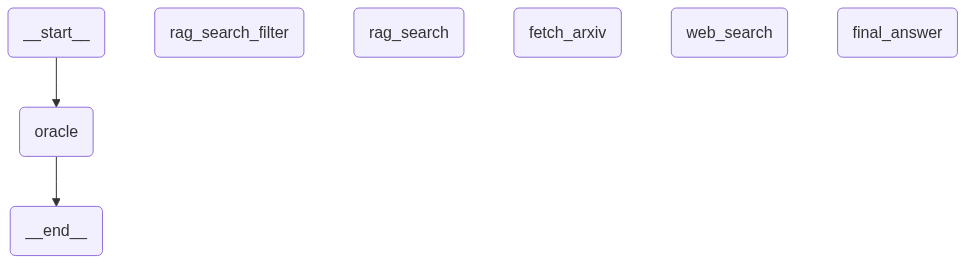

In [97]:
from IPython.display import Image, display
display(Image(runnable.get_graph().draw_mermaid_png()))

In [86]:
output = runnable.invoke({
    'input': 'Tell me something interesting about Dynamic Backtracking AI and LLMs',
    'chat_history': [],
})

run_oracle
intermediate_steps: []
rag_search.invoke(input={'query': 'dynamic backtracking algorithm constraint satisfaction, dynamic backtracking AI, relevance to modern AI and LLMs'})
run_oracle
intermediate_steps: [AgentAction(tool='rag_search', tool_input={'query': 'dynamic backtracking algorithm constraint satisfaction, dynamic backtracking AI, relevance to modern AI and LLMs'}, log='TBD'), AgentAction(tool='rag_search', tool_input={'query': 'dynamic backtracking algorithm constraint satisfaction, dynamic backtracking AI, relevance to modern AI and LLMs'}, log='Title: Towards sample-efficient episodic control with DAC-ML\nChunk: quence Learning, Reinforcement Learning, Distributed Adaptive Control\n1 Introduction\nWith the advent of Deep Reinforcement Learning (DRL), the last decade has\nbeen marked by several historical landmarks in the ﬁeld of Artiﬁcial Intelligence\n(AI), in terms of both scientiﬁc and societal impact. Reaching human-level per-\nformance in historically consider

In [87]:
output

{'input': 'Tell me something interesting about Dynamic Backtracking AI and LLMs',
 'chat_history': [],
 'intermediate_steps': [AgentAction(tool='rag_search', tool_input={'query': 'dynamic backtracking algorithm constraint satisfaction, dynamic backtracking AI, relevance to modern AI and LLMs'}, log='TBD'),
  AgentAction(tool='rag_search', tool_input={'query': 'dynamic backtracking algorithm constraint satisfaction, dynamic backtracking AI, relevance to modern AI and LLMs'}, log='Title: Towards sample-efficient episodic control with DAC-ML\nChunk: quence Learning, Reinforcement Learning, Distributed Adaptive Control\n1 Introduction\nWith the advent of Deep Reinforcement Learning (DRL), the last decade has\nbeen marked by several historical landmarks in the ﬁeld of Artiﬁcial Intelligence\n(AI), in terms of both scientiﬁc and societal impact. Reaching human-level per-\nformance in historically considered uniquely-human intellectual domains (such\nas chess [1], Go [2], and real-time strate

# 15 - Generating Reports: Building a Formatted Final Report

In [88]:
def build_report(output: dict) -> str:
    '''Builds a formatted report based on the oracle's output.

    Args:
        output (dict): A dictionary containing the various sections of the report (graph's output).

    Returns:
        str: A formatted string containing the full research report.
    '''
    research_steps = output['research_steps']
    if isinstance(research_steps, list):
        research_steps = '\n'.join([f'- {r}' for r in research_steps])

    sources = output['sources']
    if isinstance(sources, list):
        sources = '\n'.join([f'- {s}' for s in sources])

    return f"""
        INTRODUCTION
        ------------
        {output['introduction']}
        
        RESEARCH STEPS
        --------------
        {research_steps}
        
        REPORT
        ------
        {output['main_body']}
        
        CONCLUSION
        ----------
        {output['conclusion']}
        
        SOURCES
        -------
        {sources}
    """

In [89]:
output = runnable.invoke({
    'input': 'Tell me something interesting about Dynamic Backtracking AI and LLMs',
    'chat_history': [],
})

run_oracle
intermediate_steps: []
rag_search.invoke(input={'query': 'Dynamic backtracking algorithm constraint satisfaction AI applications dynamic backtracking and large language models interactions'})
run_oracle
intermediate_steps: [AgentAction(tool='rag_search', tool_input={'query': 'Dynamic backtracking algorithm constraint satisfaction AI applications dynamic backtracking and large language models interactions'}, log='TBD'), AgentAction(tool='rag_search', tool_input={'query': 'Dynamic backtracking algorithm constraint satisfaction AI applications dynamic backtracking and large language models interactions'}, log='Title: Towards sample-efficient episodic control with DAC-ML\nChunk: loop [12], allowing DAC-ML to rapidly transition from an initial exploration\nphase to a more exploitative phase in which the behavior of the agent stabilizes\nover time while maximizing reward acquisition.\nWith this work, we seek to contribute to the available proposed solutions to\nthe sample-ineﬃcien

In [92]:
output['intermediate_steps'][-1].tool_input

{'introduction': 'User asked for something interesting about Dynamic Backtracking (DBT) and Large Language Models (LLMs). This report summarizes core ideas of DBT, why it matters, and interesting intersections and research opportunities when pairing DBT-style constraint solving with LLMs.',
 'research_steps': ['Reviewed classical sources describing Dynamic Backtracking (Ginsberg 1993) and summaries of backtracking improvements for CSPs.',
  'Searched for applied uses of dynamic/non-chronological backtracking in scheduling, planning, and configuration.',
  'Searched the recent literature and public web for work combining symbolic constraint solving or search with large language models, and for general ideas on hybrid neuro-symbolic systems.',
  'Synthesized possible integration points, benefits, and risks of combining DBT methods with LLM-guided heuristics or verification loops.',
  'Compiled sources and summarized implications and open questions for research and applications.'],
 'main

In [93]:
output = runnable.invoke({
    'input': 'tell me about FIFA World Cup 26',
    'chat_history': []
})

run_oracle
intermediate_steps: []
web_search.invoke(input={'query': 'FIFA World Cup 2026 overview hosts United States Canada Mexico dates teams format 48 teams venues schedule knockout format expansion details and stadium list news'})
run_oracle
intermediate_steps: [AgentAction(tool='web_search', tool_input={'query': 'FIFA World Cup 2026 overview hosts United States Canada Mexico dates teams format 48 teams venues schedule knockout format expansion details and stadium list news'}, log='TBD'), AgentAction(tool='web_search', tool_input={'query': 'FIFA World Cup 2026 overview hosts United States Canada Mexico dates teams format 48 teams venues schedule knockout format expansion details and stadium list news'}, log='2026 FIFA World Cup: Key Dates, Host Countries and ...\nThe tournament will take place from June 11 to July 19, 2026, jointly hosted by sixteen cities: eleven in the United States, three in Mexico, ...\nhttps://go.sportconn.com/2026-fifa-world-cup-key-dates-host-countries/\n---

In [94]:
report = build_report(
    output=output['intermediate_steps'][-1].tool_input
)

print(report)


        INTRODUCTION
        ------------
        The 2026 FIFA World Cup (commonly called World Cup 2026 or FIFA World Cup 26) is the 23rd edition of the men’s FIFA World Cup. It will be held in North America and marks several historic firsts: the tournament expands to 48 teams and is jointly hosted by three countries — the United States, Mexico and Canada.

        RESEARCH STEPS
        --------------
        - Reviewed official tournament announcements and schedules from FIFA and major sports outlets.
- Checked host-city and stadium confirmations, venue counts, and opening/final match allocations.
- Collected information on the tournament format, match counts, and qualification implications for confederations and host nations.
- Reviewed ticketing, broadcasting, and travel/logistics notes and common FAQs for fans.

        REPORT
        ------
        Hosts, dates and scale: The 2026 World Cup is jointly hosted by the United States, Mexico and Canada — the first time three countr

In [98]:
output = runnable.invoke({
    'input': 'Create a summary about this AxXiv paper with the ID 2409.17990',
    'chat_history': []
})

run_oracle
intermediate_steps: []
fetch_arxiv.invoke(input={'arxiv_id': '2409.17990'})
run_oracle
intermediate_steps: [AgentAction(tool='fetch_arxiv', tool_input={'arxiv_id': '2409.17990'}, log='TBD'), AgentAction(tool='fetch_arxiv', tool_input={'arxiv_id': '2409.17990'}, log='This paper proposes temporally aligned Large Language Models (LLMs) as a tool for longitudinal analysis of social media data. We fine-tune Temporal Adapters for Llama 3 8B on full timelines from a panel of British Twitter users, and extract longitudinal aggregates of emotions and attitudes with established questionnaires. We focus our analysis on the beginning of the COVID-19 pandemic that had a strong impact on public opinion and collective emotions. We validate our estimates against representative British survey data and find strong positive, significant correlations for several collective emotions. The obtained estimates are robust across multiple training seeds and prompt formulations, and in line with collec

In [99]:
report = build_report(
    output=output['intermediate_steps'][-1].tool_input
)

print(report)


        INTRODUCTION
        ------------
        You asked for a summary of arXiv paper 2409.17990. The paper proposes temporally aligned Large Language Models (LLMs) for longitudinal analysis of social media, focusing on emotional and opinion trajectories around the start of the COVID-19 pandemic using a British Twitter panel.

        RESEARCH STEPS
        --------------
        - Fetched the paper abstract and metadata from arXiv (ID 2409.17990).
- Identified the core technical approach: Temporal Adapters fine-tuned on Llama 3 8B using full user timelines.
- Extracted the key evaluation setup and results: validation against representative British survey data, robustness checks, and comparison with a traditional labeled-classifier approach.
- Condensed contributions, strengths, and likely limitations into a concise summary suitable for a quick read.

        REPORT
        ------
        Aim and scope: The paper introduces temporally aligned LLMs as a tool for longitudinal social-

In [100]:
output = runnable.invoke({
    'input': 'Create a summary about the future of LLM Agents.',
    'chat_history': []
})

report = build_report(
    output=output['intermediate_steps'][-1].tool_input
)

print(report)

run_oracle
intermediate_steps: []
rag_search.invoke(input={'query': 'Future of LLM agents: trends, capabilities, architectures, tool use, decision-making, safety, alignment, multi-agent systems, applications, and regulatory/ethical issues.'})
run_oracle
intermediate_steps: [AgentAction(tool='rag_search', tool_input={'query': 'Future of LLM agents: trends, capabilities, architectures, tool use, decision-making, safety, alignment, multi-agent systems, applications, and regulatory/ethical issues.'}, log='TBD'), AgentAction(tool='rag_search', tool_input={'query': 'Future of LLM agents: trends, capabilities, architectures, tool use, decision-making, safety, alignment, multi-agent systems, applications, and regulatory/ethical issues.'}, log='Title: Modelling Human Routines: Conceptualising Social Practice Theory for Agent-Based Simulation\nChunk: Agent Systems. Artiﬁcial Intelligence and Law 21(1), 79–107 (8 2012),http://link.springer.com/10.1007/\ns10506-012-9128-5\nDey, A.K.: Understanding